In [228]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import pandas as pd

In [229]:
###Helper

from pathlib import Path


def save_plot(fig, filename):
    output_dir = Path("plots")
    output_dir.mkdir(exist_ok=True)
    print("Saved a figure")
    fig.savefig(output_dir / f"{filename}.pdf", bbox_inches="tight",transparent=True)


def plot_loglog(x, y, label_x, label_y, ax=None, label=""):
    if ax is None:
        fig, ax = plt.subplots()
    ax.plot(x, y, "o", label=label)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(label_x)
    ax.set_ylabel(label_y)
    if label != "":
        ax.legend()
    return ax

### a)

In [230]:
def a(scherrate, scherviskositaet, filename="viscosity_fit"):
    fig, ax = plt.subplots()
    ax.plot(scherrate, scherviskositaet, "o")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"shear rate $\dot \gamma$ [s$^{-1}$]")
    ax.set_ylabel(r"shear viscosity $\eta$ [Pa$\cdot$s]")
    nullscher_cross, kappa_cross = fit_cross(scherrate, scherviskositaet, ax)
    nullscher_carr, kappa_carr = fit_carreau(scherrate, scherviskositaet, ax)
    ax.legend()
    save_plot(fig, filename)
    print(f"""Cross
 Nullscher: {nullscher_cross}
 kappa {kappa_cross}
Carr
 Nullscher: {nullscher_carr}
 kappa {kappa_carr}""")


def cross(scherrate, n, kappa, nullscherviskositaet, hochscherviskositaet):
    return hochscherviskositaet + (nullscherviskositaet - hochscherviskositaet) / (1 + (kappa * scherrate) ** n)


def carreau(scherrate, n, kappa, nullscherviskositaet, hochscherviskositaet):
    return hochscherviskositaet + (nullscherviskositaet - hochscherviskositaet) / (
            (1 + (kappa * scherrate) ** 2) ** (n / 2))


def fit_cross(scherrate, scherviskositaet, ax):
    opt, cov = curve_fit(cross, scherrate, scherviskositaet)
    ax.plot(scherrate, cross(scherrate, *opt), label=rf"""fit according to the cross model
    $n={np.format_float_scientific(opt[0], 3)}$
    $\kappa={np.format_float_scientific(opt[1], 3)}$ s
    $\eta_0={np.format_float_scientific(opt[2], 3)}$ Pa$\cdot$s
    $\eta_\infty={np.format_float_scientific(opt[3], 3)}$ Pa$\cdot$s""")
    return opt[-2,], opt[1]


def fit_carreau(scherrate, scherviskositaet, ax):
    opt, cov = curve_fit(carreau, scherrate, scherviskositaet)
    ax.plot(scherrate, carreau(scherrate, *opt), label=rf"""fit according to the carreau model
    $n={np.format_float_scientific(opt[0], 3)}$
    $\kappa={np.format_float_scientific(opt[1], 3)}$ s
    $\eta_0={np.format_float_scientific(opt[2], 3)}$ Pa$\cdot$s
    $\eta_\infty={np.format_float_scientific(opt[3], 3)}$ Pa$\cdot$s""")
    return opt[-2,], opt[1]

### b)

In [231]:
def b(gamma1, gamma7, schubspannung1, schubspannung7, g11, g21, g17, g27, lvr, filename="moduli"):
    y_label = r"storage and loss modulus $G^{\prime}$ & $G^{\prime\prime}$ [Pa]"
    ax_1_gamma = plot_loglog(gamma1, g21, r"deformation $\gamma$ [-]", y_label, label="loss modulus at $1$ Hz")
    plot_loglog(gamma1, g11, r"deformation $\gamma$", y_label, ax=ax_1_gamma, label="modulus at 1 Hz")
    ax_7_gamma = plot_loglog(gamma7, g17, r"deformation $\gamma$", y_label, label="storage modulus at 7 Hz")
    plot_loglog(gamma7, g27, r"deformation $\gamma$", y_label, ax=ax_7_gamma, label="loss modulus at 7 Hz")

    ax_1_gamma.axvline(lvr[0], label="cutoff point of the lvr", color="red")
    ax_1_gamma.legend()
    save_plot(ax_1_gamma.figure, f"{filename}_1hz_deformation")

    ax_7_gamma.axvline(lvr[1], label="cutoff point of the lvr", color="red")
    ax_7_gamma.legend()
    save_plot(ax_7_gamma.figure, f"{filename}_7hz_deformation")

    ax_1_omega = plot_loglog(schubspannung1, g11, r"shear stress $\sigma$", y_label, label="storage modulus bei 1 Hz")
    plot_loglog(schubspannung1, g21, r"shear stress $\sigma$", y_label, ax=ax_1_omega, label="storage modulus bei 1 Hz")
    ax_7_omega = plot_loglog(schubspannung7, g17, r"shear stress $\sigma$", y_label, label="storage modulus at 7 Hz")
    plot_loglog(schubspannung7, g27, r"shear stress $\sigma$", y_label, ax=ax_7_omega, label="storage modulus at 7 Hz")

    save_plot(ax_1_omega.figure, f"{filename}_1hz_stress")
    save_plot(ax_7_omega.figure, f"{filename}_7hz_stress")

    return ax_1_gamma, ax_7_gamma, ax_1_omega, ax_7_omega

### c)

In [232]:
import numpy as np
from scipy.optimize import curve_fit


def maxwell_joint(xdata, tau, g0):
    omega, curve_id = xdata

    x = omega * tau
    denominator = 1 + x ** 2

    g1_pred = g0 * x ** 2 / denominator
    g2_pred = g0 * x / denominator

    # 0 = storage modulus G'
    # 1 = loss modulus G''
    return np.where(curve_id == 0, g1_pred, g2_pred)


def c(frequenz, g1, g2, lvr_index, filename="maxwell_fit"):
    frequenz = np.asarray(frequenz, dtype=float)
    g1 = np.asarray(g1, dtype=float)
    g2 = np.asarray(g2, dtype=float)

    winkelfrequenz = 2 * np.pi * frequenz

    ax = plot_loglog(
        winkelfrequenz,
        g1,
        r"Angular frequency $\omega$ [rad$\cdot$s$^{-1}$]",
        r"Modulus $G^\prime, G^{\prime\prime}$ [Pa]",
        label="Storage modulus G'"
    )

    plot_loglog(
        winkelfrequenz,
        g2,
        r"Angular frequency $\omega$ [rad$\cdot$s$^{-1}$]",
        r"Modulus $G^\prime, G^{\prime\prime}$ [Pa]",
        ax=ax,
        label="Loss modulus G''"
    )

    omega_fit = winkelfrequenz[:lvr_index]
    g1_data = g1[:lvr_index]
    g2_data = g2[:lvr_index]

    omega_all = np.concatenate([omega_fit, omega_fit])

    curve_id = np.concatenate([
        np.zeros(len(omega_fit)),
        np.ones(len(omega_fit))
    ])

    g_all = np.concatenate([g1_data, g2_data])

    scale_g1 = np.sqrt(np.mean(g1_data ** 2))
    scale_g2 = np.sqrt(np.mean(g2_data ** 2))

    sigma = np.concatenate([
        np.full(len(g1_data), scale_g1),
        np.full(len(g2_data), scale_g2)
    ])

    opt, cov = curve_fit(
        maxwell_joint,
        (omega_all, curve_id),
        g_all,
        p0=[0.1, 50],  # tau [s], G0 [Pa]
        sigma=sigma,
        absolute_sigma=False,
        bounds=([1e-10, 1e-10], [np.inf, np.inf]),
        maxfev=20000
    )

    tau_fit, g0_fit = opt

    x = winkelfrequenz * tau_fit
    denominator = 1 + x ** 2

    g1_model = g0_fit * x ** 2 / denominator
    g2_model = g0_fit * x / denominator

    ax.plot(
        winkelfrequenz,
        g1_model,
        "--",
        label="Maxwell fit G'"
    )

    ax.plot(
        winkelfrequenz,
        g2_model,
        "--",
        label="Maxwell fit G''"
    )

    ax.legend()
    save_plot(ax.figure, filename)

    print(f"""
Joint Maxwell fit (scaled)
--------------------------
Relaxation time tau = {tau_fit:.5f} s
Plateau modulus G0  = {g0_fit:.3f} Pa
Zero-shear viscosity = {tau_fit * g0_fit:.3f} Pa s
""")

    return tau_fit, g0_fit, cov

### d)

In [233]:
def d(g1, g2, g0, filename="cole_cole"):
    fig, ax = plt.subplots()
    ax.scatter(g1, g2)
    ax.set_xlabel(r"storage modulus  G$^\prime$ [Pa]")
    ax.set_ylabel(r"loss modulus G$^{\prime\prime}$ [Pa]")

    x = np.linspace(g1[0], g1[-1], 100, )
    calc_g2 = np.sqrt(x * (g0 - x))

    ax.plot(x, calc_g2, label="cole-cole-plot", color="red")
    ax.legend()
    save_plot(fig, filename)

Saved a figure
Cross
 Nullscher: 3.4512168470712226
 kappa 0.038574992128838394
Carr
 Nullscher: 3.4394926788903692
 kappa 0.05752389808748947
Saved a figure
Saved a figure
Saved a figure
Saved a figure
Saved a figure

Joint Maxwell fit (scaled)
--------------------------
Relaxation time tau = 0.05153 s
Plateau modulus G0  = 53.677 Pa
Zero-shear viscosity = 2.766 Pa s

Saved a figure
Saved a figure


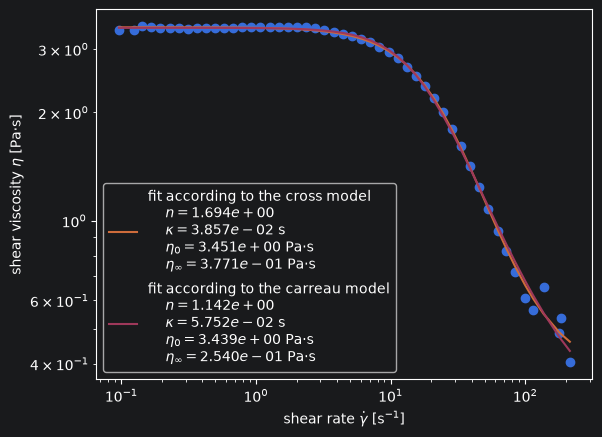

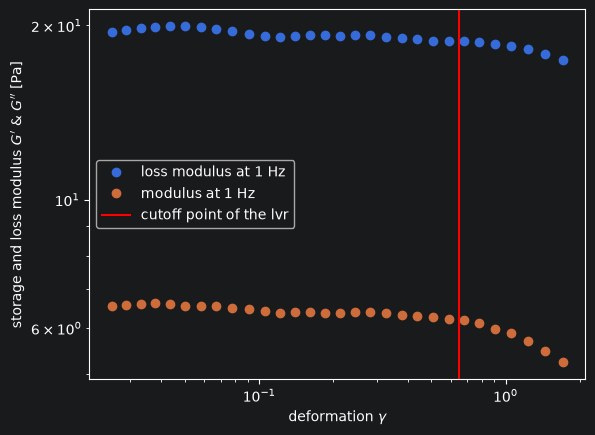

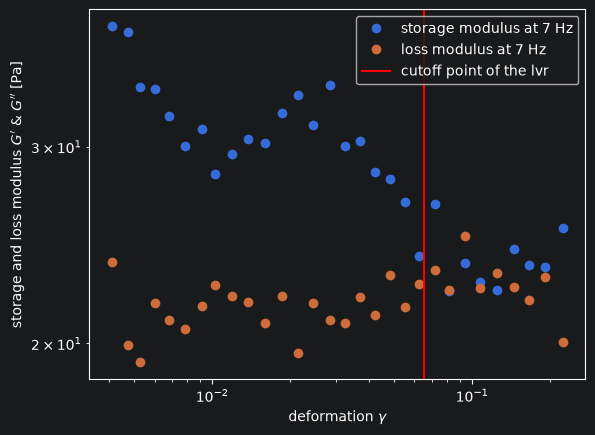

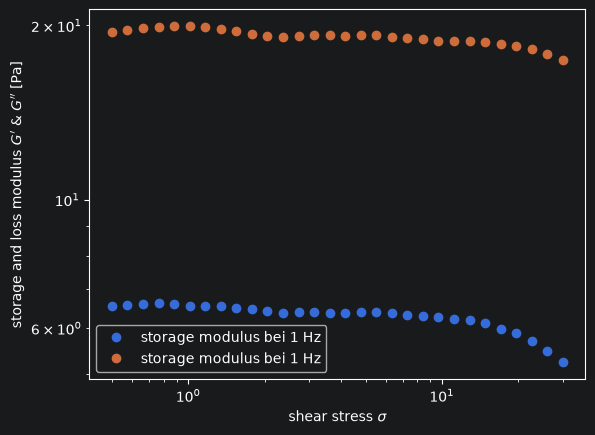

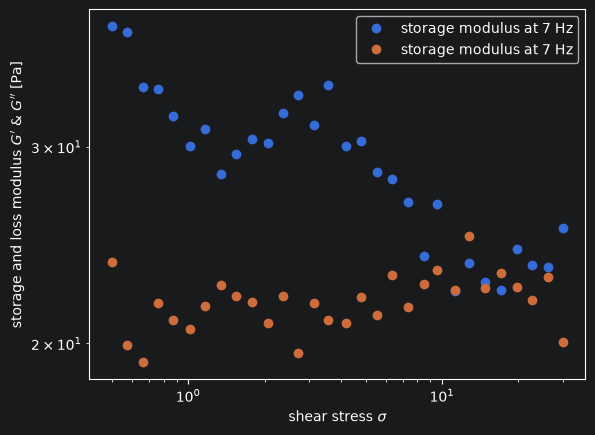

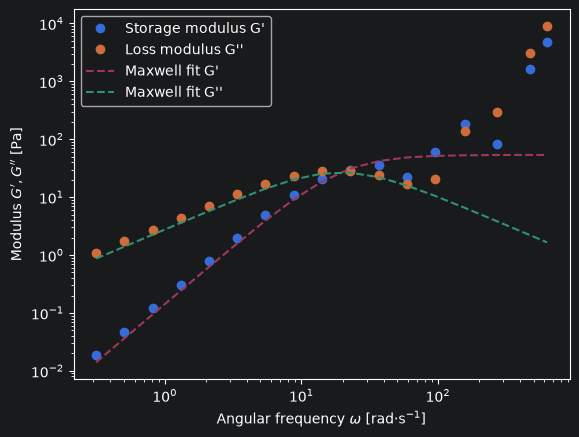

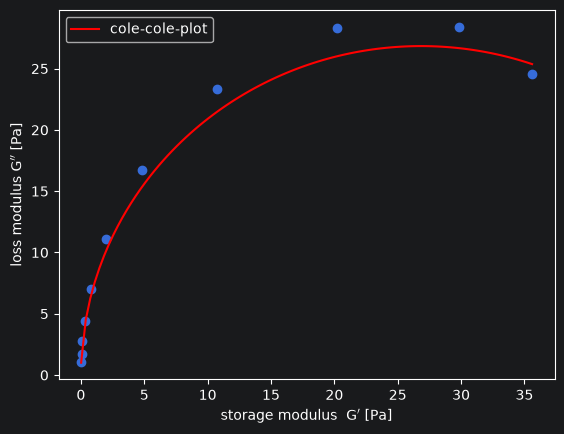

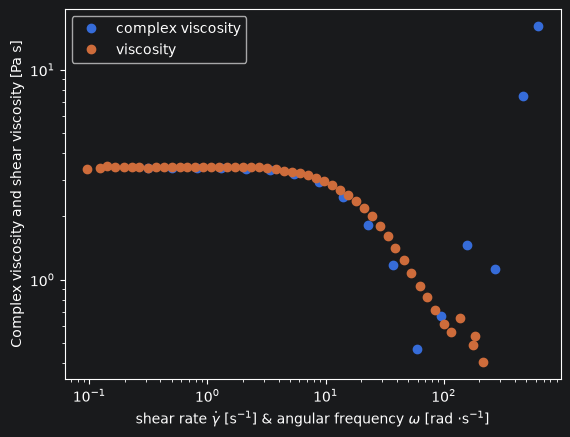

In [237]:
viskositaet_niedrigviskos = np.loadtxt("Niedrigviskos-250-viskositaet.txt", encoding="latin-1", skiprows=1, unpack=True)

scherviskos = viskositaet_niedrigviskos[2]
scherrate = viskositaet_niedrigviskos[0]

a(scherrate, scherviskos, filename="low_viscosity_fit")
n_deform_1, n_schubspannung_1, n_g1_1, n_g2_1 = np.loadtxt("Niedrigviskos-250-1hz.txt", encoding="latin1", skiprows=1,
                                                           usecols=[9, 8, 4, 5], unpack=True)
n_deform_7, n_schubspannung_7, n_g1_7, n_g2_7 = np.loadtxt("Niedrigviskos-7hz-250.txt", encoding="latin1", skiprows=1,
                                                           usecols=[9, 8, 4, 5], unpack=True)

# Zeit s	Temperatur °C	Frequenz Hz	Komp. Schubmodul Pa	Elastischer Modul Pa	Viskoser Modul Pa	Komplexe Viskosität Pas	Phasenwinkel °	Schubspannung Pa	Deformation  	Summierte Zeit s	Eta'' Pas	Dynamische Viskosität Pas	Hinweis

b(n_deform_1,n_deform_7,n_schubspannung_1,n_schubspannung_7,n_g1_1,n_g2_1,n_g1_7,n_g2_7,[0.65,0.065], filename="low_viscosity_moduli")


n_oszilla = np.loadtxt("Niedrigviskos-250-oszillation.txt", encoding="latin-1", skiprows=1, unpack=True,
                       usecols=range(0, 13))
frequenz = n_oszilla[2]
g1 = n_oszilla[4]
g2 = n_oszilla[5]
_,g0,_= c(frequenz, g1, g2, 11, filename="low_viscosity_maxwell_fit")

g1 = n_oszilla[4][:11]
g2 = n_oszilla[5][:11]

d(g1, g2, g0, filename="low_viscosity_cole_cole")
g1
n_oszilla = np.loadtxt("Niedrigviskos-250-oszillation.txt", encoding="latin-1", skiprows=1, unpack=True,
                       usecols=range(0, 13))
cvisk = n_oszilla[6]
freq = n_oszilla[2]

viskositaet_niedrigviskos = np.loadtxt("Niedrigviskos-250-viskositaet.txt", encoding="latin-1", skiprows=1, unpack=True)

scherviskos = viskositaet_niedrigviskos[2]
scherrate = viskositaet_niedrigviskos[0]

ax = plot_loglog(2 * pi * freq, cvisk, "Kreisfreq", "Kompvisk", label="complex viscosity")
plot_loglog(scherrate, scherviskos,
            r"shear rate $\dot \gamma$ [s$^{-1}$] & angular frequency $\omega$ [rad $\cdot$s$^{-1}$]", "Complex viscosity and shear viscosity [Pa s]",
            ax=ax, label="viscosity")
save_plot(ax.figure, "low_viscosity_complex_viscosity")

/tmp/ipykernel_27000/1628314194.py:21: RuntimeWarning: invalid value encountered in power
  return hochscherviskositaet + (nullscherviskositaet - hochscherviskositaet) / (1 + (kappa * scherrate) ** n)


Saved a figure
Cross
 Nullscher: 27.27240328445722
 kappa 0.258691395645653
Carr
 Nullscher: 27.078716986930427
 kappa 0.38559811436292063
Saved a figure
Saved a figure
Saved a figure
Saved a figure
Saved a figure

Joint Maxwell fit (scaled)
--------------------------
Relaxation time tau = 0.47351 s
Plateau modulus G0  = 55.986 Pa
Zero-shear viscosity = 26.510 Pa s

Saved a figure
Saved a figure


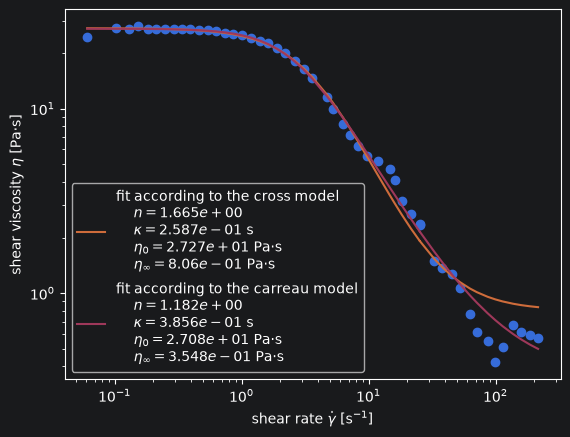

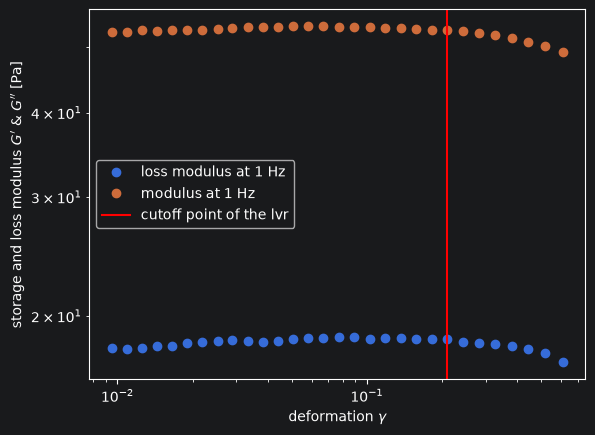

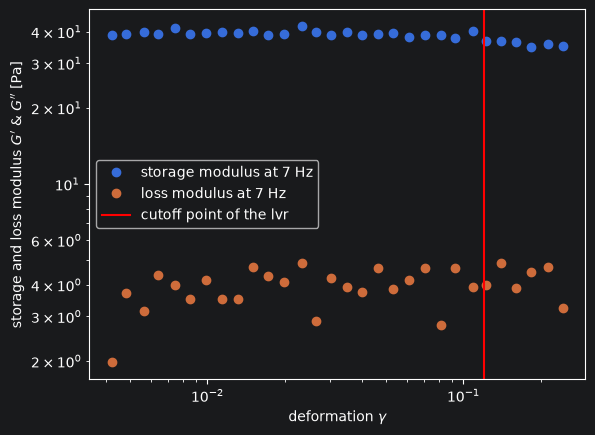

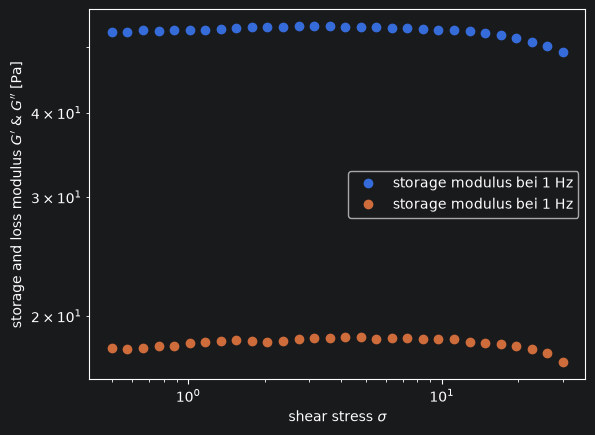

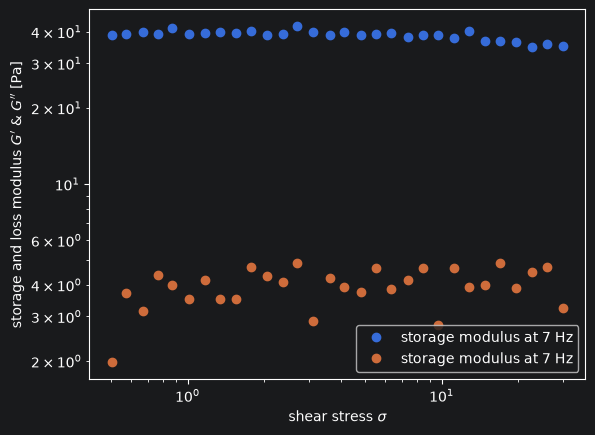

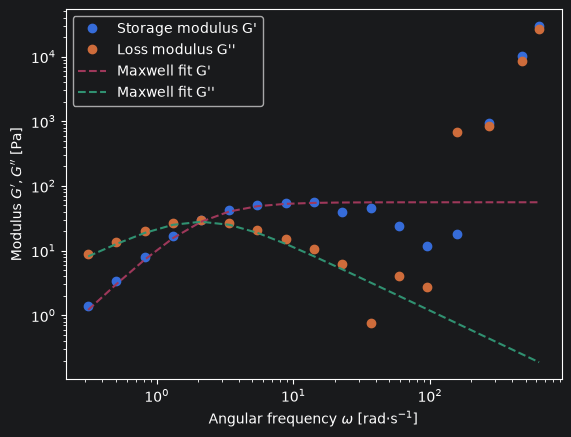

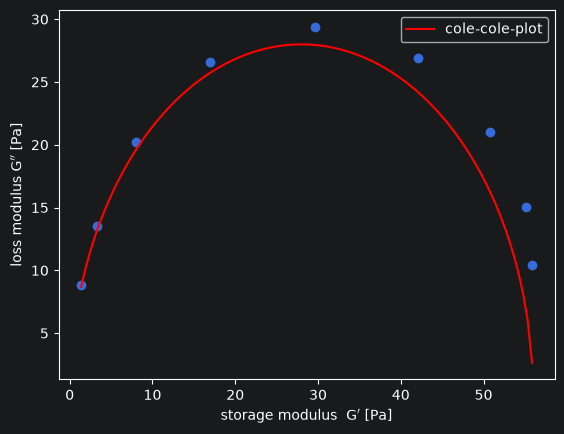

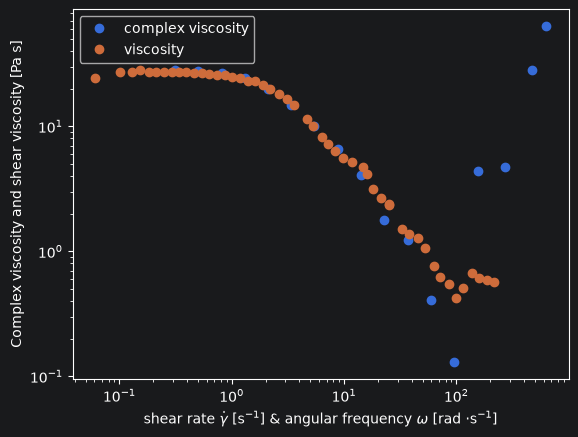

In [238]:
hochvisk_viskos = np.loadtxt("Hochviskos-viskositaet.txt", encoding="latin-1", skiprows=1, unpack=True)

scherviskos = hochvisk_viskos[2]
scherrate = hochvisk_viskos[0]

a(scherrate, scherviskos, filename="high_viscosity_fit")

h_deform_1, h_schubspannung_1, h_g1_1, h_g2_1 = np.loadtxt("Hochviskos-1hz.txt", encoding="latin1", skiprows=1,
                                                           usecols=[9, 8, 4, 5], unpack=True)
h_deform_7, h_schubspannung_7, h_g1_7, h_g2_7 = np.loadtxt("Hochviskos-7hz-richtig.txt", encoding="latin1", skiprows=1,
                                                           usecols=[9, 8, 4, 5], unpack=True)

# Zeit s	Temperatur °C	Frequenz Hz	Komp. Schubmodul Pa	Elastischer Modul Pa	Viskoser Modul Pa	Komplexe Viskosität Pas	Phasenwinkel °	Schubspannung Pa	Deformation  	Summierte Zeit s	Eta'' Pas	Dynamische Viskosität Pas	Hinweis

b(h_deform_1, h_deform_7, h_schubspannung_1, h_schubspannung_7, h_g1_1, h_g2_1, h_g1_7, h_g2_7, [.21, .12], filename="high_viscosity_moduli")

h_oszilla = np.loadtxt("Hochviskos-oszillation.txt", encoding="latin-1", skiprows=1, unpack=True, usecols=range(0, 13))
frequenz = h_oszilla[2]
g1 = h_oszilla[4]
g2 = h_oszilla[5]
_,g0,_=c(frequenz, g1, g2, 11, filename="high_viscosity_maxwell_fit")
g1 = h_oszilla[4][0:9]
g2 = h_oszilla[5][0:9]

d(g1, g2, g0, filename="high_viscosity_cole_cole")
g1
cvisk = h_oszilla[6]
freq = h_oszilla[2]

scherviskos = hochvisk_viskos[2]
scherrate = hochvisk_viskos[0]

ax = plot_loglog(2 * pi * freq, cvisk, "Kreisfreq", "Kompvisk", label="complex viscosity")
plot_loglog(scherrate, scherviskos,
            r"shear rate $\dot \gamma$ [s$^{-1}$] & angular frequency $\omega$ [rad $\cdot$s$^{-1}$]", "Complex viscosity and shear viscosity [Pa s]",
            ax=ax, label="viscosity")
save_plot(ax.figure, "high_viscosity_complex_viscosity")